# GH-band demod testing

## Changes
### Dpipe Source Code

cuts.py:

- VSSAmpBase defines seg_length as an int or a string, but span.get_segments() requires n (int) and unit (string): created helper function VSSAmpBase._get_slices() to run get_segments() according to datatype of seg_length

modulator.py: ModulatorObs

- enc_factor is found from Dpipe/data/ModData/g_band/current/mod_data.yml instead (since it is not in mod_config)

### Config File

demod_processing: 

- Temp and Pol filters have merged into LowPass (resolves errors in get_temp and demod)
- stokes_params must be specified (resolves errors in postprocess)

could possibly add this (as defined in demod):

    # Set default Stokes parameters based on modulator type
    if hasattr(span.config, 'stokes_params'):
        stokes_params = span.config.stokes_params
    else:
        if isinstance(self.mod_in_tel.mod, VPM):
            stokes_params = ['u', 'v']  # Default for VPM
        elif isinstance(self.mod_in_tel.mod, RHWP):
            stokes_params = ['q', 'u']  # Default for RHWP
        else:
            raise ValueError('Unknown modulator type')

In [1]:
%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

from Dpipe import startup, repkg, pipe
from Dpipe import timeseries_util as tsu
from Dpipe import cuts, filtering, modulator

# Verify environment
print('DPIPE_PREFIX =', os.getenv('DPIPE_PREFIX'))
print('MAPMAKING_IN =', os.getenv('MAPMAKING_IN'))
assert os.getenv('DPIPE_PREFIX'), "Set DPIPE_PREFIX before running"

dpipe_path = os.getenv('DPIPE_PREFIX')

vpm_cfg = startup.DpipeConfig(os.path.join(dpipe_path, '/home/viviantao1/class_code/Dpipe/parameter_files/gh_vivian_test.yml'))
print(f"VPM config: recv={vpm_cfg.recv}, timeline={vpm_cfg.timeline}")
print(f"  UIDs: {vpm_cfg.uids}")

DPIPE_PREFIX = /home/viviantao1/class_code
MAPMAKING_IN = /data/users/class/mapmaking_in/
VPM config: recv=gh_band, timeline=g_vivian_test
  UIDs: [0, 1, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 29, 30, 31, 32, 34, 35, 36, 37, 38, 52, 53, 54, 58, 59, 60, 62, 63, 65, 66, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 82, 83, 112, 113, 161, 182, 183, 224, 225, 226, 227, 228, 229, 230, 231, 232, 352, 353, 354, 355, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 372, 373, 375, 376, 377, 378, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 392, 396, 397, 398, 399, 403, 404, 405, 406, 410, 411, 412, 413, 414, 415, 416, 417, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 434, 435, 464, 465, 513, 595, 596, 597, 599, 600, 601, 602, 603, 604, 606, 607, 609, 705, 706, 707, 709, 712, 714, 722, 724, 725, 726, 727, 729, 748, 749, 750, 751, 752, 753, 754, 755, 758, 760, 761, 762, 763, 764, 765, 766, 767, 768, 770, 

In [22]:
ctime_file = np.load('/data/users/class/mapmaking_in/dtod/gh_band/gh_vivian_test/2023-08-09-22-10-00_78/ctime.npz')
i = np.load('/data/users/class/mapmaking_in/dtod/gh_band/gh_vivian_test/2023-08-09-22-10-00_78/i.npy')
u = np.load('/data/users/class/mapmaking_in/dtod/gh_band/gh_vivian_test/2023-08-09-22-10-00_78/u.npy')
v = np.load('/data/users/class/mapmaking_in/dtod/gh_band/gh_vivian_test/2023-08-09-22-10-00_78/v.npy')

In [23]:
ctime = ctime_file['ctime']

In [24]:
det_idx = 5
i_det = i[det_idx]
u_det = u[det_idx]
v_det = v[det_idx]

Text(0.5, 0, 'Time')

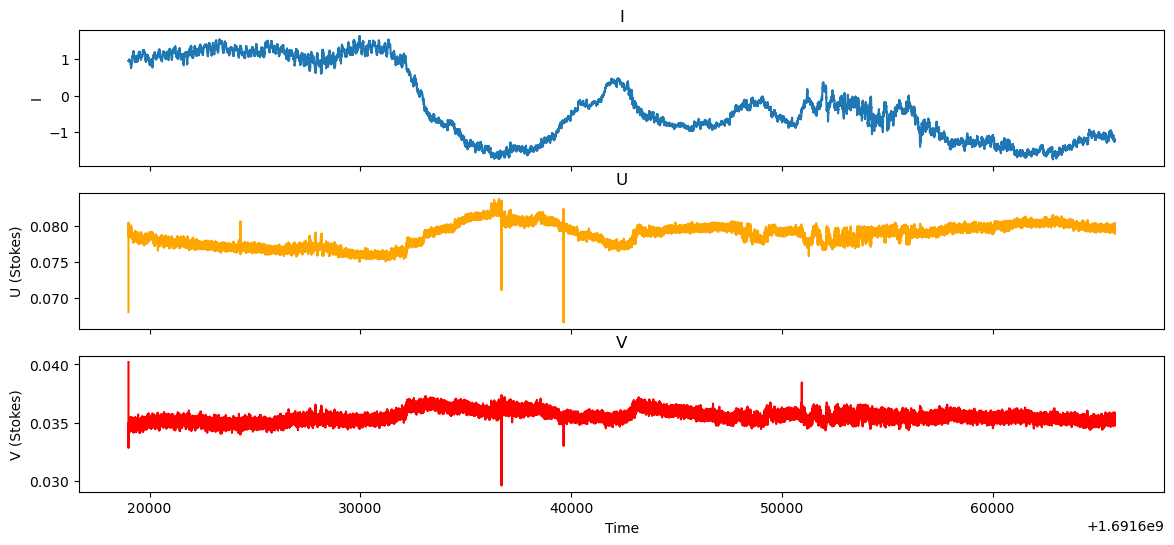

In [25]:
fig, ax = plt.subplots(3, 1, figsize=(14, 6), sharex=True)
ax[0].plot(ctime, i_det)
ax[0].set_title("I")
ax[0].set_ylabel("I")
ax[1].plot(ctime, u_det, color='orange')
ax[1].set_title("U")
ax[1].set_ylabel("U (Stokes)")
ax[2].plot(ctime, v_det, color='red')
ax[2].set_title("V")
ax[2].set_ylabel("V (Stokes)")
ax[2].set_xlabel("Time")